# Wildfire Evacuation Alert-Failure — Data Analysis

Loads the CSVs produced by `collect_data.py` (GDELT news coverage + Reddit
submissions/comments/subreddit-local for the Lahaina and Camp Fire case
studies) and runs burst detection on each, to compare when informal online
awareness spiked against the official warning timeline from each AG/
investigation report.

**In Colab:** run the cells top to bottom. The second code cell will prompt
you to upload CSVs — select all of them at once (multi-select works in the
picker): `lahaina_*.csv`, `camp_fire_*.csv`, including any
`*_reddit_local.csv` / `*_reddit_local_comments.csv` files you have.

**Running locally instead:** no upload needed — `DATA_DIR` defaults to
`../data`, the project's `data/` folder (this notebook lives in `src/`).

In [1]:
!pip install -q pandas matplotlib

In [2]:
import os

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    pass

DATA_DIR = "../data"  # project's data/ folder (notebook lives in src/)

if IN_COLAB:
    from google.colab import files
    print("Select all your CSVs (lahaina_*.csv, camp_fire_*.csv, *_reddit_local*.csv) "
          "-- multi-select is fine.")
    uploaded = files.upload()
    DATA_DIR = "."

print(f"Looking for CSVs in: {os.path.abspath(DATA_DIR)}")

Looking for CSVs in: /Users/aneeshghosal/Documents/ML/data


## Discover which CSVs are present

In [3]:
import glob

CASES = ["lahaina", "camp_fire"]
SOURCE_SUFFIXES = {
    "gdelt": "_gdelt.csv",
    "reddit_submissions": "_reddit_submissions.csv",
    "reddit_comments": "_reddit_comments.csv",
}

def find_case_files(case, data_dir=DATA_DIR):
    found = {}
    for label, suffix in SOURCE_SUFFIXES.items():
        path = os.path.join(data_dir, f"{case}{suffix}")
        if os.path.exists(path):
            found[label] = path
    # Subreddit-local files are named <case>_<subreddit>_reddit_local.csv
    for path in sorted(glob.glob(os.path.join(data_dir, f"{case}_*_reddit_local.csv"))):
        sub = os.path.basename(path).replace(f"{case}_", "").replace("_reddit_local.csv", "")
        found[f"local_{sub}"] = path
    # ...and their comments: <case>_<subreddit>_reddit_local_comments.csv
    for path in sorted(glob.glob(os.path.join(data_dir, f"{case}_*_reddit_local_comments.csv"))):
        sub = os.path.basename(path).replace(f"{case}_", "").replace("_reddit_local_comments.csv", "")
        found[f"local_comments_{sub}"] = path
    return found

case_files = {case: find_case_files(case) for case in CASES}
for case, found in case_files.items():
    print(f"{case}: found {list(found.keys())}")
    missing_core = set(SOURCE_SUFFIXES) - set(found)
    if missing_core:
        print(f"  (missing: {sorted(missing_core)} -- rerun collect_data.py for these if you need them)")

lahaina: found ['gdelt', 'reddit_submissions', 'reddit_comments', 'local_Hawaii', 'local_Maui', 'local_comments_Hawaii', 'local_comments_Maui']
camp_fire: found ['gdelt', 'reddit_submissions', 'reddit_comments', 'local_California', 'local_Chico', 'local_comments_California', 'local_comments_Chico']


## Load each CSV and parse timestamps

In [4]:
import pandas as pd

def load_with_timestamp(path, timestamp_col):
    try:
        df = pd.read_csv(path, low_memory=False)
    except pd.errors.EmptyDataError:  # e.g. a subreddit with no posts in the window
        df = pd.DataFrame()
        df["_timestamp"] = pd.Series(dtype="datetime64[ns]")
        return df
    if timestamp_col not in df.columns:
        print(f"  ! '{timestamp_col}' not in {os.path.basename(path)}; columns: {list(df.columns)}")
        df["_timestamp"] = pd.NaT
        return df
    col = df[timestamp_col]
    if col.dtype == object and col.astype(str).str.contains("T").any():
        # GDELT-style: 20230809T120000Z
        ts = pd.to_datetime(col, format="%Y%m%dT%H%M%SZ", errors="coerce", utc=True)
    else:
        # Reddit-style: unix epoch seconds
        ts = pd.to_datetime(col, unit="s", errors="coerce", utc=True)
    # naive UTC for every source, so GDELT and Reddit times (and the official
    # timeline) can be compared and subtracted
    df["_timestamp"] = ts.dt.tz_convert(None)
    return df

data = {}  # data[case][source_label] = DataFrame with a "_timestamp" column
for case, found in case_files.items():
    data[case] = {}
    for label, path in found.items():
        ts_col = "seendate" if label == "gdelt" else "created_utc"
        df = load_with_timestamp(path, ts_col)
        data[case][label] = df
        n_valid = df["_timestamp"].notna().sum()
        if n_valid:
            print(f"{case} / {label}: {len(df)} rows, "
                  f"{df['_timestamp'].min()} to {df['_timestamp'].max()}")
        else:
            print(f"{case} / {label}: {len(df)} rows, no valid timestamps")

lahaina / gdelt: 3875 rows, 2023-08-08 17:00:00 to 2023-08-12 00:45:00
lahaina / reddit_submissions: 212 rows, 2023-08-09 08:02:56 to 2023-08-11 03:58:34
lahaina / reddit_comments: 445 rows, 2023-08-09 02:59:56 to 2023-08-11 03:39:00
lahaina / local_Hawaii: 187 rows, 2023-08-08 04:02:45 to 2023-08-11 03:58:34
lahaina / local_Maui: 333 rows, 2023-08-08 07:57:05 to 2023-08-11 03:50:32
lahaina / local_comments_Hawaii: 4163 rows, 2023-08-08 04:01:11 to 2023-08-11 03:59:37
lahaina / local_comments_Maui: 3900 rows, 2023-08-08 11:58:17 to 2023-08-10 20:17:15
camp_fire / gdelt: 1641 rows, 2018-11-08 18:00:00 to 2018-11-13 00:45:00
camp_fire / reddit_submissions: 72 rows, 2018-11-08 21:18:08 to 2018-11-12 00:53:18
camp_fire / reddit_comments: 55 rows, 2018-11-08 23:03:31 to 2018-11-12 04:14:50
camp_fire / local_California: 230 rows, 2018-11-08 07:46:50 to 2018-11-12 03:57:48
camp_fire / local_Chico: 0 rows, no valid timestamps
camp_fire / local_comments_California: 2903 rows, 2018-11-08 05:00:1

## Burst detection

Same approach as `analyze_burst.py`: bin each source into hourly buckets and
z-score each hour against the **24 hours before it** (the hour itself is not
part of its own baseline). The spread is floored at Poisson noise
(`sqrt(mean)`, min 1) so a near-silent baseline can't make a handful of posts
look like a spike, and nothing is flagged until 6 hours of history exist.
A burst is z ≥ 3.

Note the local-subreddit sources are *everything* posted there, not just
fire-related posts, so their bursts can partly reflect the normal daily
rhythm (e.g. a morning rise in activity). Check them against the content
cell at the bottom before reading too much into them.

In [5]:
import numpy as np

def compute_burst(timestamps, freq="h", baseline_window=24, z_threshold=3.0, min_baseline=6):
    """Count events per `freq` bucket and z-score each bucket against the
    `baseline_window` buckets *before* it (the bucket itself is excluded --
    including it, as an earlier version did, caps z at (n-1)/sqrt(n), about
    2.04 for a 6-bucket window, so real spikes never cleared the threshold).
    The std is floored at sqrt(mean) (Poisson noise, min 1) so a near-empty
    baseline can't turn a handful of posts into a huge z. No burst can be
    flagged until `min_baseline` buckets of history exist."""
    ts = timestamps.dropna()
    if ts.empty:
        return pd.DataFrame(columns=["count", "baseline_mean", "z_score", "burst"])
    counts = ts.dt.floor(freq).value_counts().sort_index()
    counts = counts.asfreq(freq, fill_value=0)
    prior = counts.shift(1)
    mean = prior.rolling(baseline_window, min_periods=min_baseline).mean()
    std = prior.rolling(baseline_window, min_periods=min_baseline).std()
    noise_floor = np.maximum(np.sqrt(mean), 1)
    z = (counts - mean) / np.maximum(std, noise_floor)
    result = pd.DataFrame({"count": counts, "baseline_mean": mean, "z_score": z})
    result["burst"] = result["z_score"] >= z_threshold
    return result

burst_results = {}
for case in CASES:
    burst_results[case] = {}
    for label, df in data[case].items():
        result = compute_burst(df["_timestamp"])
        burst_results[case][label] = result
        if not result.empty and result["burst"].any():
            first_burst = result.index[result["burst"]].min()
            print(f"{case} / {label}: first burst at {first_burst}")
        else:
            max_z = result["z_score"].max() if not result.empty else float("nan")
            print(f"{case} / {label}: no burst (max z {max_z:.2f}, {len(df)} rows)")

lahaina / gdelt: first burst at 2023-08-09 11:00:00
lahaina / reddit_submissions: first burst at 2023-08-09 21:00:00
lahaina / reddit_comments: first burst at 2023-08-09 08:00:00
lahaina / local_Hawaii: first burst at 2023-08-09 08:00:00
lahaina / local_Maui: first burst at 2023-08-09 10:00:00
lahaina / local_comments_Hawaii: first burst at 2023-08-08 18:00:00
lahaina / local_comments_Maui: first burst at 2023-08-09 06:00:00
camp_fire / gdelt: first burst at 2018-11-09 04:00:00
camp_fire / reddit_submissions: no burst (max z 2.67, 72 rows)
camp_fire / reddit_comments: first burst at 2018-11-09 20:00:00
camp_fire / local_California: no burst (max z 2.96, 230 rows)
camp_fire / local_Chico: no burst (max z nan, 0 rows)
camp_fire / local_comments_California: first burst at 2018-11-08 14:00:00
camp_fire / local_comments_Chico: no burst (max z nan, 0 rows)


## Official timeline

One entry per documented event, copied from the investigation reports
(Hawaii AG report for Lahaina; the Camp Fire investigation / after-action
reports). Each entry has:

- **`local_time`**: `"YYYY-MM-DD HH:MM"` **in local time, exactly as the
  report gives it**. It's converted to UTC using the case's time zone
  (Lahaina: HST, UTC-10; Camp Fire: PST, UTC-8), because all the data is in UTC.
  Leave it `None` until it's pinned down; unfilled events are listed and
  left off the plots.
- **`category`**: one of `ignition`, `warning`, `evacuation`, `fire_arrival`,
  `casualty`, `other`. Used for colors and the lag table.
- **`channel`**: how it reached people (or didn't): e.g. `"WEA"`,
  `"EAS"`, `"siren"`, `"social media"`, `"phone/text"`, `"door-to-door"`,
  `"news"`, `"not activated"`. Leave `None` where it doesn't apply.
- **`source`**: citation with page/section, so every timestamp is traceable.

Add as many entries as you need (multiple warnings, each evacuation zone, etc.).

In [6]:
CASE_TIMEZONES = {
    "lahaina": "Pacific/Honolulu",       # HST, UTC-10 (no daylight saving)
    "camp_fire": "America/Los_Angeles",  # PST, UTC-8 on Nov 8 2018
}
CATEGORIES = ["ignition", "warning", "evacuation", "fire_arrival", "casualty", "other"]

OFFICIAL_TIMELINE = {
    "lahaina": [
        {"event": "Ignition",                       "category": "ignition",
         "local_time": None, "channel": None, "source": ""},
        {"event": "First public warning",           "category": "warning",
         "local_time": None, "channel": None, "source": ""},
        {"event": "First evacuation order",         "category": "evacuation",
         "local_time": None, "channel": None, "source": ""},
        {"event": "Fire reaches Lahaina town",      "category": "fire_arrival",
         "local_time": None, "channel": None, "source": ""},
    ],
    "camp_fire": [
        {"event": "Ignition",                       "category": "ignition",
         "local_time": None, "channel": None, "source": ""},
        {"event": "First public warning",           "category": "warning",
         "local_time": None, "channel": None, "source": ""},
        {"event": "First evacuation order",         "category": "evacuation",
         "local_time": None, "channel": None, "source": ""},
        {"event": "Fire reaches Paradise",          "category": "fire_arrival",
         "local_time": None, "channel": None, "source": ""},
    ],
}


def build_timeline(official=OFFICIAL_TIMELINE, tzs=CASE_TIMEZONES):
    """Flatten OFFICIAL_TIMELINE into one DataFrame with a UTC time column
    (naive UTC, to match the data), flagging anything unfilled or malformed."""
    rows = []
    for case, events in official.items():
        for e in events:
            row = {"case": case, **e, "time_utc": pd.NaT, "problem": ""}
            if e.get("category") not in CATEGORIES:
                row["problem"] = f"unknown category {e.get('category')!r}"
            if e.get("local_time"):
                try:
                    local = pd.Timestamp(e["local_time"]).tz_localize(tzs[case])
                    row["time_utc"] = local.tz_convert("UTC").tz_localize(None)
                except Exception as ex:
                    row["problem"] = f"bad local_time ({ex})"
                if not e.get("source"):
                    row["problem"] = (row["problem"] + "; " if row["problem"] else "") + "no source"
            rows.append(row)
    return pd.DataFrame(rows).sort_values(["case", "time_utc"], na_position="last")


timeline = build_timeline()
filled = timeline[timeline["time_utc"].notna()]
print(f"{len(filled)} of {len(timeline)} events have a time.\n")
if not filled.empty:
    print(filled[["case", "event", "category", "channel", "local_time", "time_utc"]]
          .to_string(index=False))
unfilled = timeline[timeline["time_utc"].isna()]
if not unfilled.empty:
    print("\nStill to fill in:")
    for _, r in unfilled.iterrows():
        print(f"  {r['case']}: {r['event']}")
problems = timeline[timeline["problem"] != ""]
if not problems.empty:
    print("\nCheck these:")
    for _, r in problems.iterrows():
        print(f"  {r['case']}: {r['event']} -- {r['problem']}")

0 of 8 events have a time.


Still to fill in:
  camp_fire: Ignition
  camp_fire: First public warning
  camp_fire: First evacuation order
  camp_fire: Fire reaches Paradise
  lahaina: Ignition
  lahaina: First public warning
  lahaina: First evacuation order
  lahaina: Fire reaches Lahaina town


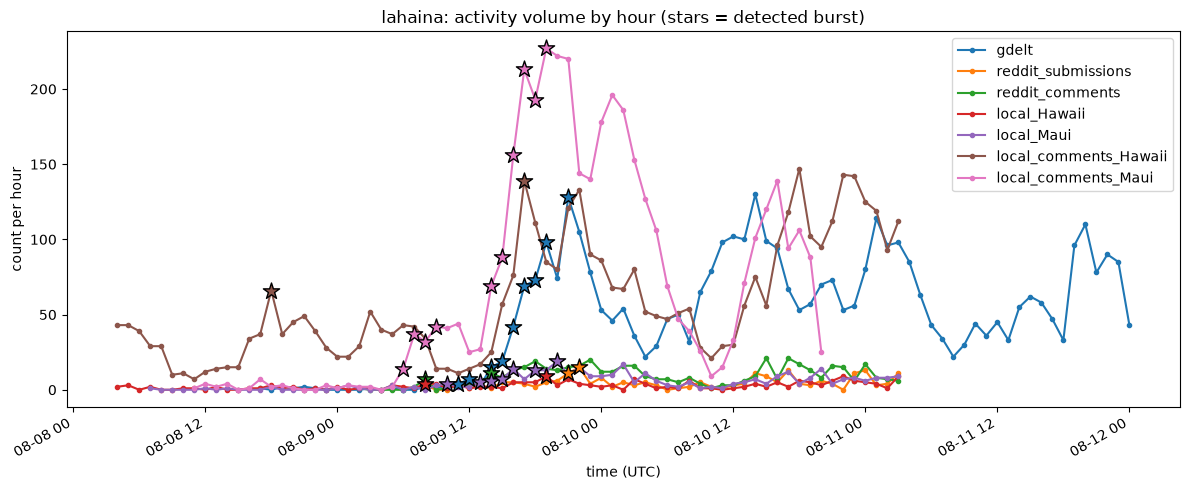

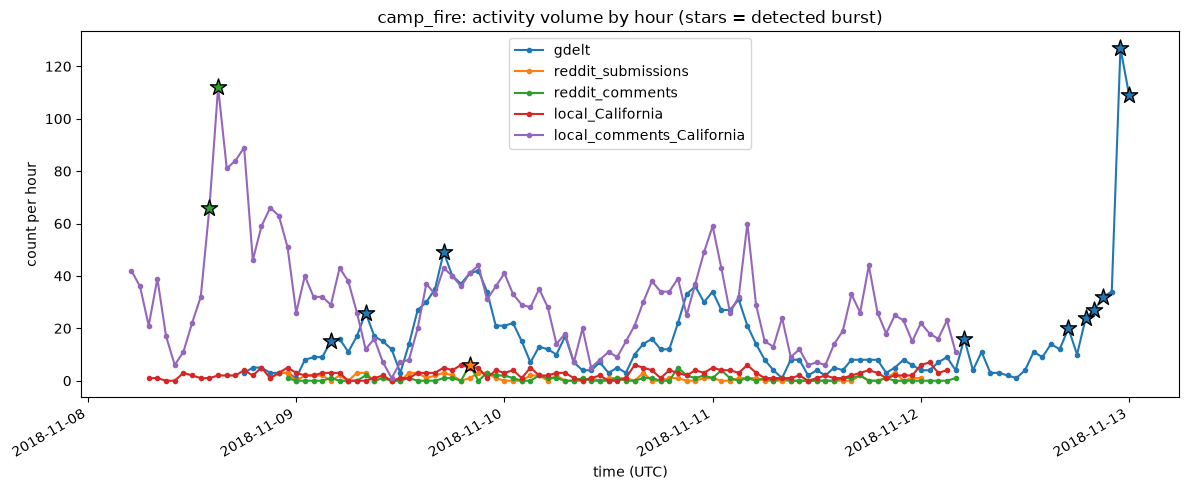

In [7]:
import matplotlib.pyplot as plt

def plot_case_timeline(case):
    fig, ax = plt.subplots(figsize=(12, 5))
    plotted_any = False
    for label, result in burst_results[case].items():
        if result.empty:
            continue
        plotted_any = True
        ax.plot(result.index, result["count"], marker="o", markersize=3, label=label)
        bursts = result[result["burst"]]
        if not bursts.empty:
            ax.scatter(bursts.index, bursts["count"], marker="*", s=150, zorder=5,
                       edgecolors="black")

    category_colors = dict(zip(CATEGORIES, ["black", "red", "darkorange", "purple",
                                            "dimgray", "teal"]))
    events = timeline[(timeline["case"] == case) & timeline["time_utc"].notna()]
    for _, e in events.iterrows():
        color = category_colors.get(e["category"], "teal")
        ax.axvline(e["time_utc"], linestyle="--", color=color, alpha=0.7)
        label = e["event"] + (f" ({e['channel']})" if e["channel"] else "")
        ax.text(e["time_utc"], ax.get_ylim()[1] * 0.95, label, rotation=90, color=color,
                fontsize=8, va="top")

    if not plotted_any:
        print(f"{case}: nothing to plot (no sources with valid timestamps)")
        plt.close(fig)
        return

    ax.set_title(f"{case}: activity volume by hour (stars = detected burst)")
    ax.set_xlabel("time (UTC)")
    ax.set_ylabel("count per hour")
    ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

for case in CASES:
    plot_case_timeline(case)

## Lag: public activity vs. the official timeline

For each official event, hours between it and each source's **first
detected burst**. Positive means the burst came *after* the event; negative
means public activity spiked *before* it (e.g. people were talking about
the fire before the first warning went out). This is the core comparison
for the response-gap question.

In [8]:
lag_rows = []
for case in CASES:
    events = timeline[(timeline["case"] == case) & timeline["time_utc"].notna()]
    for label, result in burst_results[case].items():
        if result.empty or not result["burst"].any():
            continue
        first_burst = result.index[result["burst"]].min()
        for _, e in events.iterrows():
            lag_rows.append({
                "case": case,
                "source": label,
                "first_burst_utc": first_burst,
                "event": e["event"],
                "hours_after_event": round((first_burst - e["time_utc"]).total_seconds() / 3600, 1),
            })

if lag_rows:
    lags = pd.DataFrame(lag_rows)
    for case, g in lags.groupby("case"):
        print(f"\n=== {case}: hours from official event to first burst (negative = burst first) ===")
        print(g.pivot(index="source", columns="event", values="hours_after_event").to_string())
else:
    print("Nothing to compare yet -- fill in OFFICIAL_TIMELINE times above.")

Nothing to compare yet -- fill in OFFICIAL_TIMELINE times above.


## Quick content check
Sample titles/text per source, so you can eyeball whether the keyword search actually pulled relevant content.

In [9]:
for case in CASES:
    print(f"\n=== {case} ===")
    for label, df in data[case].items():
        print(f"\n-- {label} ({len(df)} rows) --")
        if "title" in df.columns:
            print(df["title"].head(5).to_string(index=False))
        elif "body" in df.columns:
            print(df["body"].astype(str).str.slice(0, 120).head(5).to_string(index=False))
        if "domain" in df.columns:
            print("Top domains:")
            print(df["domain"].value_counts().head(10))
        if "subreddit" in df.columns:
            print("Subreddit breakdown:")
            print(df["subreddit"].value_counts().head(10))


=== lahaina ===

-- gdelt (3875 rows) --
Death toll from Maui wildfires rises to 67 as s...
Maui wildfires live updates : Death toll climbs...
Death toll from Maui wildfires rises to 67 as s...
Death toll in Maui disaster hits 67 , deadliest...
Maui wildfires live updates : Lahaina resembles...
Top domains:
domain
yahoo.com               71
kitv.com                58
cnn.com                 30
caledonianrecord.com    29
dailymail.co.uk         24
iheart.com              21
usatoday.com            20
staradvertiser.com      20
abc7news.com            19
independent.co.uk       19
Name: count, dtype: int64

-- reddit_submissions (212 rows) --
           Front Street in Lahaina on fire (video)
                              Lahaina town on fire
BREAKING: Extremely dangerous massive wildfire ...
Almost all sides of Maui, Hawaii is currently o...
Lahaina fire (and kudos to Walmart and American...
Top domains:
domain
i.redd.it              25
self.maui              16
v.redd.it              